# 같은 과제로 다섯 패턴 비교

**이 노트북에서 할 일**

1. 01~05절의 흐름 함수 다섯을 도구 파일에서 가져와, 같은 과제 글로 한 번씩 실행합니다.
2. 흐름마다 요청 수·토큰 수·걸린 초·코드 검사 점수·상태를 표 한 줄로 만듭니다.
3. 다섯 줄을 한 표로 견주고, 흐름의 모양이 정한 값과 실행마다 달라진 값을 가립니다.
4. 코드 검사의 최소 글자 수만 바꿔, 같은 안내문의 품질 칸이 어떻게 달라지는지 봅니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델 `gpt-5.4-mini`에 보내는 요청 수는 흐름마다 다릅니다.
단계 잇기와 라우팅은 많아야 2번, 나눠 쓰기는 부분 수만큼 3번 보냅니다.
작업 나눠 맡기기는 1 + 작업 수 + 1이라 많아야 6번입니다.
쓰고 평가하기 반복은 바퀴 수의 두 배라 많아야 6번입니다.

그래서 이 노트북은 많아야 19번 보냅니다. 교재 출력을 만든 실행에서는 14번 보냈습니다.
노트북 밖에서 같은 흐름을 보낸 기록의 토큰 수로 어림한 예상 비용은 미화 0.01달러 아래입니다.
실제 청구 금액과는 다를 수 있습니다.

자료 파일을 읽거나 새 파일을 쓰지 않습니다.
01~05절에서 배운 함수는 같은 폴더의 도구 파일 `workflow_tools.py`에서 가져옵니다.
흐름마다 걸린 초를 잽니다. 교재 출력을 만든 실행에서는 노트북 전체가 약 22초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 openai 2.29.0과 python-dotenv 1.2.3을 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~3절과 9절을 읽습니다.
같은 과제와 표 한 줄을 만드는 함수, 그리고 비교 표를 읽는 자리입니다.
4~8절은 흐름 다섯을 차례로 실행하는 자리이고, 10절은 값 바꿔 보기입니다.
이 부분은 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch18-workflow-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![왼쪽에서 오른쪽으로 읽는 그림으로 왼쪽 초록 상자 과제 글 공통 사실 코드 검사 값 120~180자에서 가운데 파란 상자 다섯, 곧 위에서부터 01 단계 잇기 run_gated_chain, 02 라우팅 route_question, 03 나눠 쓰기 write_sections, 04 작업 나눠 맡기기 run_orchestrator, 05 쓰고 평가하기 반복 run_write_judge_loop로 갈라지고, 다섯이 모두 오른쪽 노란 상자 비교 표 다섯 줄 칸 여섯 두 번 모두 상태 ok 다섯으로 모이는 그림](attachment:06-1-같은-과제를-다섯-흐름에.png)

왼쪽에서 오른쪽으로 읽습니다. 왼쪽 초록 상자의 과제 글과 코드 검사 값을 가운데 파란 흐름 다섯이 똑같이 받습니다.
흐름마다 만든 표 한 줄이 오른쪽 노란 비교 표로 모입니다.
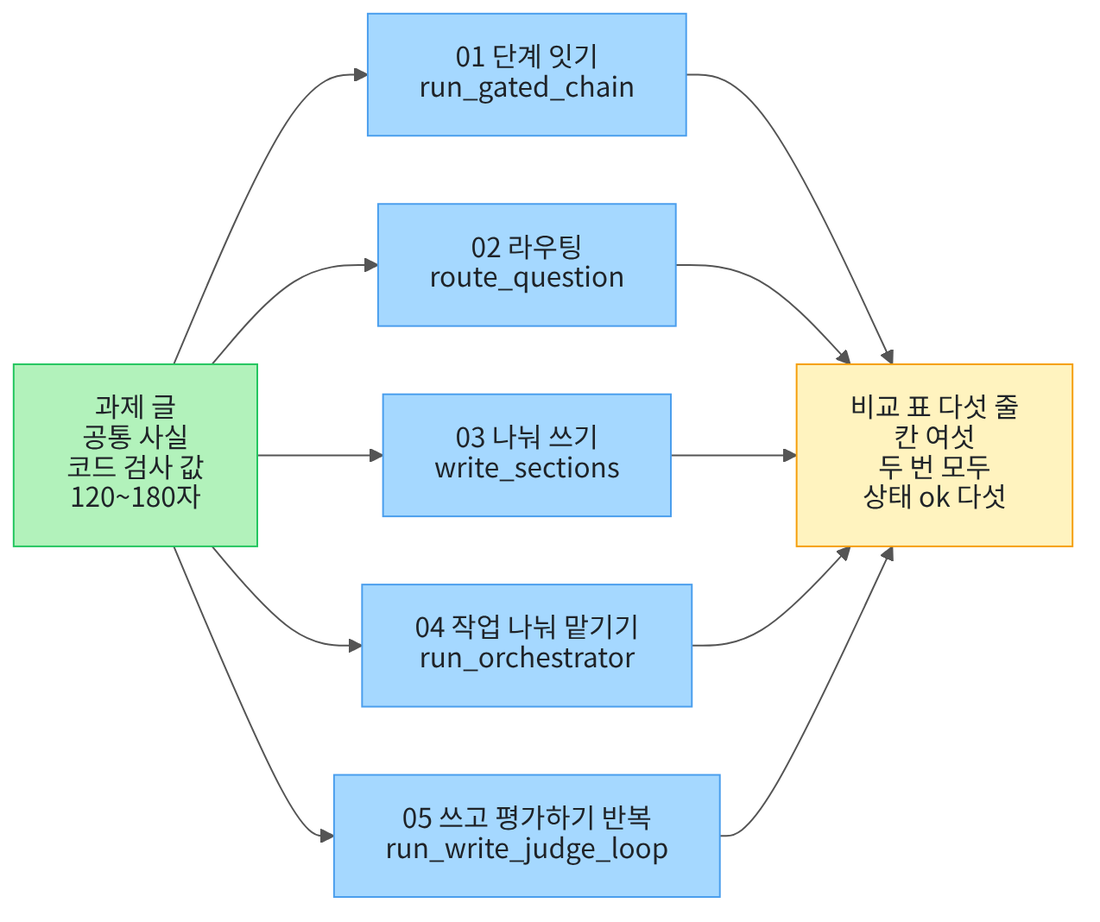

## 1. 준비

이 절은 01~05절에서 만든 흐름 다섯을 같은 과제 글로 한 번씩 실행해 견줍니다.
흐름 함수는 새로 적지 않고 도구 파일에서 가져옵니다.
첫 셀은 패키지 두 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "openai==2.29.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


openai: 2.29.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `openai: 2.29.0`과 `python-dotenv: 1.2.3`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `workflow_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
다음 셀은 시간을 재는 모듈 `time`과 클라이언트 이름, 01~05절 함수 여섯을 가져옵니다.

In [2]:
# 시간을 재는 모듈 time과 클라이언트 이름 OpenAI, 01~05절 함수 여섯을 가져옵니다
import time

from openai import OpenAI

from workflow_tools import check_draft, route_question, run_gated_chain, run_orchestrator, run_write_judge_loop, write_sections

print("불러온 이름:", "time", "OpenAI", "check_draft", "route_question")
print("불러온 이름:", "run_gated_chain", "run_orchestrator", "run_write_judge_loop", "write_sections")

불러온 이름: time OpenAI check_draft route_question
불러온 이름: run_gated_chain run_orchestrator run_write_judge_loop write_sections


**결과 읽기** — 두 출력 줄 `불러온 이름:` 뒤에 가져온 이름 여덟이 있습니다.
흐름 함수 다섯은 01절 `run_gated_chain`, 02절 `route_question`, 03절 `write_sections`입니다.
04절 `run_orchestrator`와 05절 `run_write_judge_loop`도 흐름 함수입니다.
함수 `check_draft`는 05절 코드 검사 함수로, 이 절에서는 품질 칸을 셀 때 씁니다.
모듈 `time`은 03절처럼 걸린 초를 잴 때 씁니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄 `OPENAI_API_KEY 설정 여부: True`로 키를 찾았습니다.
키 값은 출력하지 않습니다.

다음 셀은 01~05절처럼 `client = OpenAI()` 한 줄로 클라이언트를 만듭니다.

In [4]:
# OpenAI 서비스에 요청을 보낼 클라이언트를 하나 만듭니다(키는 앞 셀에서 읽은 환경 변수를 씁니다)
client = OpenAI()
print("클라이언트:", type(client).__name__)

클라이언트: OpenAI


**결과 읽기** — 출력 줄 `클라이언트: OpenAI`로 클라이언트를 만들었습니다.
다섯 흐름의 요청은 모두 이 클라이언트 하나로 보냅니다.

## 2. 같은 과제와 코드 검사 값

흐름끼리 견주려면 다섯 흐름에 같은 재료를 줘야 합니다.
과제가 다르면 표의 차이가 흐름에서 왔는지, 과제에서 왔는지 가를 수 없습니다.
다음 셀은 03~05절과 같은 공통 사실을 적습니다.

In [5]:
# 다섯 흐름이 함께 쓸 공통 사실을 적습니다(01~05절과 같은 날짜·까닭·등록 방법·문의처)
notice_fact = "2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. "
notice_fact = notice_fact + "비밀번호만으로는 계정을 지키기 어렵기 때문입니다. "
notice_fact = notice_fact + "등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. "
notice_fact = notice_fact + "문의는 help@company.test로 받습니다."
print("공통 사실:")
print(notice_fact)

공통 사실:
2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 받습니다.


**결과 읽기** — 라벨 줄 `공통 사실:` 아래 한 줄이 03~05절과 같은 공통 사실입니다.
날짜, 까닭, 등록 방법, 문의처가 한 문장씩 들어 있습니다.
코드 셀 첫 줄 주석은 「01~05절과 같은」이라고 적었지만, 이 공통 사실은 03절부터 썼습니다.
01·02절은 비밀번호 재설정 안내문과 고객 문의라는 다른 과제를 썼습니다.

다음 셀은 다섯 흐름에 똑같이 줄 과제 글을 적습니다.
과제 글의 두 요구, 곧 글자 수 범위와 꼭 담을 말은 코드 검사 값으로도 적습니다.
05절 함수 `check_draft`에 넣을 값입니다.
규칙 문장 `rule_text`는 쓰는 쪽 지시 글에 함께 넣을 문장입니다.

In [6]:
# 다섯 흐름에 똑같이 줄 과제 글과, 과제의 두 요구를 코드 검사 값으로 적습니다
task_text = "전 직원에게 보낼 2단계 인증 안내문을 120~180자로 쓰세요. 적용 날짜, 대상, 등록 방법, 문의처 주소를 담습니다."
base_text = "과제: " + task_text + "\n공통 사실: " + notice_fact
# 쓰는 쪽 지시 글에 함께 넣을 규칙 문장입니다(05절 쓰기 지시 글에 있던 문장)
rule_text = "과제의 요구를 지키고, 공통 사실에 없는 날짜·연락처·절차는 지어내지 않습니다. "
grade_setup = {"최소 글자 수": 120, "최대 글자 수": 180}
grade_setup["필수 말"] = ["10월 15일", "전 직원", "보안 메뉴", "help@company.test"]
print("과제 글:")
print(task_text)
print("코드 검사 값:", grade_setup)

과제 글:
전 직원에게 보낼 2단계 인증 안내문을 120~180자로 쓰세요. 적용 날짜, 대상, 등록 방법, 문의처 주소를 담습니다.
코드 검사 값: {'최소 글자 수': 120, '최대 글자 수': 180, '필수 말': ['10월 15일', '전 직원', '보안 메뉴', 'help@company.test']}


**결과 읽기** — 라벨 줄 `과제 글:` 아래가 다섯 흐름에 줄 과제 글입니다.
글자 수는 120자 이상 180자 이하이고, 적용 날짜·대상·등록 방법·문의처 주소를 담으라고 합니다.
출력 줄 `코드 검사 값:` 뒤 딕셔너리가 두 요구를 코드로 적은 값입니다.
이 값은 흐름을 실행하기 전에 정했고, 9절 표를 만들 때까지 바꾸지 않습니다.
변수 `base_text`는 05절처럼 과제 글과 공통 사실을 이은 글입니다.

## 3. 비교 표 한 줄을 만드는 함수

흐름 다섯의 결과를 같은 칸으로 견주려고, 흐름마다 표 한 줄을 만듭니다.
칸은 패턴 이름, 요청 수, 토큰 수, 걸린 초, 품질, 상태 여섯입니다.
요청 수는 01절에서 정한 대로 기록 줄 수입니다.
토큰 수는 기록 줄마다 입력 토큰과 출력 토큰을 모두 더한 값입니다.
다음 셀은 토큰 수를 더하는 함수입니다.

In [7]:
# 기록 목록의 줄마다 입력 토큰과 출력 토큰을 더해, 흐름 하나의 토큰 수를 내놓습니다
def total_tokens(records):
    total = 0
    for row in records:
        total = total + row["입력 토큰"] + row["출력 토큰"]
    return total

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `total_tokens`는 기록 목록을 받아 줄마다 입력 토큰과 출력 토큰을 더합니다.
기록 줄은 흐름 함수 안의 `ask_json`이 요청 한 번마다 한 줄씩 남깁니다.
03절처럼 함께 보낸 요청은 도착 차례로 쌓이지만, 더한 값은 차례와 상관없습니다.

다음 셀은 품질 칸을 세는 함수입니다.
품질은 평가 모델의 점수가 아니라, 05절 코드 검사로 셉니다.
검사 항목은 글자 수 범위 하나와 꼭 담을 말 넷, 모두 다섯입니다.

In [8]:
# 안내문을 05절 코드 검사로 보고, 항목 가운데 문제가 없는 항목 수를 내놓습니다
def grade_notice(notice, grade_setup):
    problems = check_draft(notice, grade_setup["최소 글자 수"], grade_setup["최대 글자 수"], grade_setup["필수 말"])
    # 글자 수 검사는 문제를 많아야 하나 내므로, 항목 수는 글자 수 1 + 꼭 담을 말 수입니다
    item_count = 1 + len(grade_setup["필수 말"])
    return item_count - len(problems)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `grade_notice`는 안내문과 코드 검사 값을 받아, 문제가 없는 항목 수를 내놓습니다.
글자 수 검사는 짧거나 길거나 둘 가운데 하나만 문제로 적으므로 한 항목입니다.
그래서 이 과제에서 값은 0부터 5까지의 정수입니다.
모델을 부르지 않으므로 같은 안내문에는 늘 같은 값이 나옵니다.

다음 셀은 표 한 줄을 딕셔너리 하나로 만드는 함수입니다.
흐름 결과의 칸 「상태」가 「완료」인 줄만 칸 「상태」를 `ok`로 적습니다.

In [9]:
# 흐름 하나의 기록 목록·걸린 초·상태·안내문으로 비교 표 한 줄(칸 여섯)을 딕셔너리로 만듭니다
def make_row(pattern, records, elapsed, state, notice, grade_setup):
    row = {"패턴": pattern, "요청 수": len(records), "토큰 수": total_tokens(records)}
    row["걸린 초"] = round(elapsed, 3)
    row["품질"] = grade_notice(notice, grade_setup)
    # 흐름이 끝까지 간 「완료」만 ok로 적고, 멈춤·되묻기는 그 상태를 그대로 적습니다
    row["상태"] = state
    if state == "완료":
        row["상태"] = "ok"
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `make_row`는 패턴 이름, 기록 목록, 걸린 초, 흐름의 상태, 안내문, 코드 검사 값을 받습니다.
요청 수는 기록 줄 수, 토큰 수는 함수 `total_tokens`, 품질은 함수 `grade_notice`로 셉니다.
걸린 초는 03절처럼 `round()`로 소수 셋째 자리까지 남깁니다.
「멈춤」이나 「되묻기」로 끝난 흐름은 그 상태를 그대로 적어 `ok`와 가릅니다.

다음 셀은 손으로 적은 기록 두 줄과 짧은 글 하나로 세 함수를 확인합니다.
모델 글이 아니라 미리 정한 값이라 `assert`로 확인할 수 있습니다.

In [10]:
# 손으로 적은 기록 두 줄과 글 하나로 세 함수를 확인합니다(정해 둔 값이라 assert로 봅니다)
hand_records = [{"단계": "기획", "입력 토큰": 100, "출력 토큰": 30}, {"단계": "작성", "입력 토큰": 200, "출력 토큰": 50}]
hand_setup = {"최소 글자 수": 10, "최대 글자 수": 12, "필수 말": ["보안 메뉴", "help@company.test"]}
done_row = make_row("hand", hand_records, 1.23456, "완료", "보안 메뉴에서 등록하세요.", hand_setup)
stop_row = make_row("hand", hand_records[:1], 0.5, "멈춤", "보안 메뉴에서 등록하세요.", hand_setup)
print("완료인 줄:", done_row)
print("멈춘 줄:", stop_row)
assert [done_row["토큰 수"], done_row["걸린 초"], done_row["품질"], done_row["상태"]] == [380, 1.235, 1, "ok"]
assert [stop_row["요청 수"], stop_row["토큰 수"], stop_row["상태"]] == [1, 130, "멈춤"]

완료인 줄: {'패턴': 'hand', '요청 수': 2, '토큰 수': 380, '걸린 초': 1.235, '품질': 1, '상태': 'ok'}
멈춘 줄: {'패턴': 'hand', '요청 수': 1, '토큰 수': 130, '걸린 초': 0.5, '품질': 1, '상태': '멈춤'}


**결과 읽기** — 출력 줄 `완료인 줄:`에서 토큰 수 `380`은 기록 두 줄의 네 수를 더한 값입니다.
걸린 초 1.23456은 `'걸린 초': 1.235`로 줄었습니다.
14자 글이 12자보다 길고 주소도 없어, 항목 셋 가운데 `'품질': 1`입니다.
출력 줄 `멈춘 줄:`에서는 칸 「상태」가 `'상태': '멈춤'`으로 그대로 남았습니다.
두 `assert` 줄도 통과했습니다.

## 4. 단계 잇기 — 01절 흐름

이제 흐름 다섯을 차례로 실행합니다.
흐름마다 기록 목록을 새로 만들어, 그 흐름의 요청만 담습니다.
걸린 초는 03절처럼 흐름 앞뒤에 `time.perf_counter()`로 잽니다.
흐름 하나를 통째로 잰 것은 이 절이 처음입니다.

첫 흐름은 01절 단계 잇기입니다.
01절 함수 `run_gated_chain`은 설정 딕셔너리와 기획 요청 글을 받습니다.
다음 셀은 설정 네 칸과 기획 요청 글을 만듭니다.

In [11]:
# 01절 단계 잇기의 설정: 지시 글 하나를 기획과 작성에 함께 쓰고, 기획의 칸 셋과 절차 수를 게이트가 봅니다
chain_instructions = "사내 안내문을 만드는 작성자입니다. " + rule_text + "답은 JSON 객체 하나로만 출력합니다."
plan_request = "아래 과제로 안내문을 쓰기 전에 기획을 JSON으로 적어 주세요.\n" + base_text
plan_request = plan_request + "\n「절차」에는 공통 사실의 등록 방법을 직원이 따라 할 차례로 둘 이상 나눠 적습니다."
plan_request = plan_request + '\nJSON만 출력하세요: {"제목": "글", "독자": "글", "절차": ["글", "글"]}'
chain_head = "아래 과제와 기획대로 안내문을 JSON으로 쓰세요.\n" + base_text + '\nJSON만 출력하세요: {"안내문": "글"}'
chain_setup = {"지시 글": chain_instructions, "작성 머리글": chain_head, "필수 칸": ["제목", "독자", "절차"]}
chain_setup["최소 절차 수"] = 2
print("설정 칸 수:", len(chain_setup))
print("기획 요청 글:")
print(plan_request)

설정 칸 수: 4
기획 요청 글:
아래 과제로 안내문을 쓰기 전에 기획을 JSON으로 적어 주세요.
과제: 전 직원에게 보낼 2단계 인증 안내문을 120~180자로 쓰세요. 적용 날짜, 대상, 등록 방법, 문의처 주소를 담습니다.
공통 사실: 2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 받습니다.
「절차」에는 공통 사실의 등록 방법을 직원이 따라 할 차례로 둘 이상 나눠 적습니다.
JSON만 출력하세요: {"제목": "글", "독자": "글", "절차": ["글", "글"]}


**결과 읽기** — 출력 줄 `설정 칸 수: 4`로 01절과 같은 네 칸을 모았습니다.
라벨 줄 `기획 요청 글:` 아래 다섯 줄이 첫 요청 글입니다.
첫 줄은 머리글이고, 둘째·셋째 줄은 과제 글과 공통 사실입니다.
넷째 줄은 칸 「절차」에 적을 것, 다섯째 줄은 기획의 칸 셋입니다.
게이트는 칸 셋이 있는지, 칸 「절차」가 둘 이상인 목록인지 봅니다.

다음 셀은 흐름을 실행합니다.
기획이 게이트를 지나면 작성 요청까지 두 번 보냅니다.

In [12]:
# 01절 단계 잇기 흐름을 실행하고 걸린 초를 잽니다(모델 요청 1~2번 — 게이트를 지나면 2번)
chain_records = []
start_time = time.perf_counter()
chain_result = run_gated_chain(client, chain_records, chain_setup, plan_request)
elapsed = time.perf_counter() - start_time
chain_row = make_row("chaining", chain_records, elapsed, chain_result["상태"], chain_result["안내문"], grade_setup)
print("게이트가 찾은 문제:", chain_result["문제"])
print("안내문:")
print(chain_result["안내문"])
print("글자 수:", len(chain_result["안내문"]))
print("표 한 줄:", chain_row)

게이트가 찾은 문제: []
안내문:
전 직원 대상 2단계 인증을 2026년 10월 15일부터 적용합니다. 비밀번호만으로는 계정 보호가 어려우니, 사내 포털의 보안 메뉴에서 인증 앱을 연결해 등록해 주세요. 문의는 help@company.test로 보내주시기 바랍니다.
글자 수: 129
표 한 줄: {'패턴': 'chaining', '요청 수': 2, '토큰 수': 712, '걸린 초': 3.756, '품질': 5, '상태': 'ok'}


**결과 읽기** — 출력 줄 `게이트가 찾은 문제: []`로 기획이 게이트를 지났습니다.
라벨 줄 `안내문:` 아래가 작성 요청이 쓴 안내문이고, 출력 줄 `글자 수:` 뒤 수가 그 글자 수입니다.
출력 줄 `표 한 줄:` 뒤 딕셔너리가 이 흐름의 비교 표 한 줄입니다.
표 한 줄의 `'요청 수': 2`와 `'상태': 'ok'`는 새 커널로 한 번 더 실행했을 때도 같았습니다.

안내문 글과 토큰 수, 걸린 초는 실행마다 달라질 수 있습니다.
교재 출력에서는 `글자 수: 129`, 토큰 수 712, 걸린 초 3.756이었고 품질은 5였습니다.
새 커널로 한 번 더 실행했을 때는 안내문과 토큰 수가 같았고, 걸린 초만 3.243이었습니다.
노트북 밖에서 다섯 번 보냈을 때는 117~134자였고, 한 번은 120자보다 짧아 품질 4였습니다.

## 5. 라우팅 — 02절 흐름

둘째 흐름은 02절 라우팅입니다.
이번에는 고객 문의 대신 과제 글과 공통 사실을 이은 글 `base_text`를 넣습니다.
분류 요청이 과제의 종류를 적고, 코드가 그 종류의 갈래로 보냅니다.
다음 셀은 분류 지시 글입니다. 종류는 보안, 인사, 회계 셋입니다.

In [13]:
# 02절 라우팅의 분류 지시 글: 과제를 종류 셋 가운데 하나로 가르고, 정할 수 없으면 모름으로 적게 합니다
classify_instructions = "사내 안내문 과제를 종류 하나로 가르는 분류 담당입니다. "
classify_instructions = classify_instructions + "종류는 보안, 인사, 회계 가운데 하나로 적습니다. "
classify_instructions = classify_instructions + "하나로 정할 수 없으면 종류를 모름으로 적습니다. "
# 신뢰도는 모델이 스스로 적는 수입니다(재서 얻은 값이 아님)
classify_instructions = classify_instructions + "신뢰도에는 그 종류가 맞다고 보는 정도를 0과 1 사이 수로 적습니다. "
classify_instructions = classify_instructions + '답은 JSON 객체 하나로만 출력합니다: {"종류": "글", "신뢰도": 수}'
print("분류 지시 글:")
print(classify_instructions)

분류 지시 글:
사내 안내문 과제를 종류 하나로 가르는 분류 담당입니다. 종류는 보안, 인사, 회계 가운데 하나로 적습니다. 하나로 정할 수 없으면 종류를 모름으로 적습니다. 신뢰도에는 그 종류가 맞다고 보는 정도를 0과 1 사이 수로 적습니다. 답은 JSON 객체 하나로만 출력합니다: {"종류": "글", "신뢰도": 수}


**결과 읽기** — 라벨 줄 `분류 지시 글:` 아래 한 줄이 분류 지시 글입니다.
02절 분류 지시 글과 모양이 같고, 첫 문장과 종류 이름만 이 과제에 맞게 바꿨습니다.
정할 수 없으면 종류를 모름으로 적게 한 것도 02절과 같습니다.

다음 셀은 라우팅 설정 여섯 칸을 모읍니다.
갈래마다 지시 글의 첫 문장만 다르고, 뒤는 규칙 문장과 답 모양으로 같습니다.

In [14]:
# 02절 라우팅의 설정: 종류마다 갈래의 지시 글을 두고, 허용 목록·기준값·되묻기 글을 함께 모읍니다
answer_tail = rule_text + '답은 JSON 객체 하나로만 출력합니다: {"답": "글"}'
branch_table = {"보안": "보안 안내문을 맡은 작성자입니다. " + answer_tail}
branch_table["인사"] = "인사 안내문을 맡은 작성자입니다. " + answer_tail
branch_table["회계"] = "회계 안내문을 맡은 작성자입니다. " + answer_tail
route_setup = {"분류 지시 글": classify_instructions, "요청 머리글": "아래 과제에 JSON으로 답하세요.\n", "갈래 표": branch_table}
route_setup["허용 목록"] = list(branch_table.keys())
route_setup["기준값"] = 0.75
route_setup["되묻기 글"] = "과제의 종류를 알려 주세요. 보안, 인사, 회계 가운데 어느 안내문인지 적어 주세요."
print("설정 칸 수:", len(route_setup))

설정 칸 수: 6


**결과 읽기** — 출력 줄 `설정 칸 수: 6`으로 02절과 같은 여섯 칸을 모았습니다.
허용 목록은 02절처럼 갈래 표의 칸 이름으로 만들었고, 기준값도 02절과 같은 0.75입니다.
요청 머리글에는 02절처럼 JSON이라는 말을 넣었습니다.

다음 셀은 라우팅 흐름을 실행합니다.
분류가 검사를 지나면 갈래의 답 요청까지 두 번 보냅니다.

In [15]:
# 02절 라우팅 흐름에 과제 글과 공통 사실을 이은 글을 문의로 넣고 걸린 초를 잽니다(모델 요청 1~2번)
route_records = []
start_time = time.perf_counter()
route_result = route_question(client, route_records, route_setup, base_text)
elapsed = time.perf_counter() - start_time
route_row = make_row("routing", route_records, elapsed, route_result["상태"], route_result["답"], grade_setup)
print("분류:", route_result["분류"])
print("안내문:")
print(route_result["답"])
print("글자 수:", len(route_result["답"]))
print("표 한 줄:", route_row)

분류: {'종류': '보안', '신뢰도': 0.99}
안내문:
2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 대상은 전 직원이며, 사내 포털의 보안 메뉴에서 인증 앱을 연결해 등록해 주세요. 문의는 help@company.test로 보내 주시기 바랍니다.
글자 수: 121
표 한 줄: {'패턴': 'routing', '요청 수': 2, '토큰 수': 503, '걸린 초': 2.746, '품질': 5, '상태': 'ok'}


**결과 읽기** — 출력 줄 `분류:` 뒤 딕셔너리가 분류 요청의 답입니다.
종류 `보안`은 허용 목록에 있고, 신뢰도 `0.99`는 기준값 0.75보다 높아 보안 갈래로 갔습니다.
이 분류는 새 커널로 한 번 더 실행했을 때와 노트북 밖 다섯 번에서도 같았습니다.
라벨 줄 `안내문:` 아래가 갈래의 답 요청이 쓴 안내문입니다.
출력 줄 `표 한 줄:` 뒤 딕셔너리가 이 흐름의 비교 표 한 줄입니다.

안내문 글과 글자 수, 품질은 실행마다 달라질 수 있습니다.
교재 출력에서는 121자에 품질 5, 토큰 수 503, 걸린 초 2.746이었습니다.
한 번 더 실행했을 때는 117자로 120자보다 짧아 품질이 4였고, 토큰 수는 503으로 같았습니다.
요청 수 2와 상태 `ok`는 두 번 모두 같았습니다.

## 6. 함께 보내기 — 03절 나눠 쓰기

셋째 흐름은 03절 나눠 쓰기입니다.
03절 함수 `write_sections`는 과제 글을 받지 않고, 설정의 부분 목록과 공통 사실만 받습니다.
그래서 과제가 담으라는 내용을 부분 셋으로 옮겨 적습니다.
글자 수 요구는 부분마다 한 문장으로 쓰게 하는 것으로 옮깁니다.
안내문 전체의 글자 수를 보는 요청은 이 흐름에 없습니다.

In [16]:
# 03절 나눠 쓰기의 설정: 과제가 담으라는 내용을 부분 셋으로 옮기고, 부분마다 한 문장으로 쓰게 합니다
section_instructions = "사내 안내문의 한 부분을 쓰는 작성자입니다. "
section_instructions = section_instructions + "공통 사실 가운데 쓸 부분에 맞는 것만 골라 한국어 한 문장으로 씁니다. "
section_instructions = section_instructions + "공통 사실에 없는 날짜·연락처·절차는 지어내지 않습니다. "
section_instructions = section_instructions + '답은 JSON 객체 하나로만 출력합니다: {"부분": "쓸 부분 이름 그대로", "글": "글"}'
parts = [{"이름": "적용", "담을 내용": "적용 날짜와 대상"}, {"이름": "등록", "담을 내용": "등록 방법"}]
parts.append({"이름": "문의", "담을 내용": "문의처 주소"})
sections_setup = {"지시 글": section_instructions, "요청 머리글": "아래 공통 사실로 안내문의 한 부분을 JSON으로 쓰세요.\n공통 사실: "}
sections_setup["부분"] = parts
print("부분 수:", len(parts))

부분 수: 3


**결과 읽기** — 출력 줄 `부분 수: 3`으로 부분 셋을 적었습니다.
적용 부분은 적용 날짜와 대상, 등록 부분은 등록 방법, 문의 부분은 문의처 주소를 맡습니다.
지시 글과 요청 머리글은 03절과 같고, 지시 글의 「두 문장」만 「한 문장」으로 바꿨습니다.

다음 셀은 나눠 쓰기 흐름을 실행합니다.
03절처럼 셀 맨 위에서 `await`로 부르고, 부분 셋의 요청을 함께 보냅니다.

In [17]:
# 03절 나눠 쓰기 흐름을 실행하고 걸린 초를 잽니다(모델 요청 3번 — 부분 셋을 함께 보냄)
sections_records = []
start_time = time.perf_counter()
sections_result = await write_sections(client, sections_records, sections_setup, notice_fact)
elapsed = time.perf_counter() - start_time
sections_row = make_row("parallel", sections_records, elapsed, sections_result["상태"], sections_result["안내문"], grade_setup)
print("안내문:")
print(sections_result["안내문"])
print("글자 수:", len(sections_result["안내문"]))
print("표 한 줄:", sections_row)

안내문:
2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다.
등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다.
문의는 help@company.test로 받습니다.

글자 수: 104
표 한 줄: {'패턴': 'parallel', '요청 수': 3, '토큰 수': 676, '걸린 초': 1.043, '품질': 4, '상태': 'ok'}


**결과 읽기** — 라벨 줄 `안내문:` 아래 세 줄이 부분 셋을 넣은 차례로 이은 안내문입니다.
03절 함수 `join_parts`가 부분마다 줄바꿈을 붙이므로, 글자 수에는 줄바꿈 셋도 들어갑니다.
출력 줄 `표 한 줄:`의 `'요청 수': 3`은 부분 수와 같습니다.
출력 줄 `글자 수: 104`가 120자보다 짧아, 글자 수 항목이 빠진 `'품질': 4`입니다.
부분 셋이 한 문장씩이라, 이은 글이 과제의 글자 수에 모자랐습니다.

새 커널로 한 번 더 실행했을 때도 안내문과 글자 수, 토큰 수 676이 같았습니다.
노트북 밖에서 다섯 번 보냈을 때는 104~110자였고, 다섯 번 모두 품질 4였습니다.
걸린 초는 교재 출력에서 1.043, 한 번 더 실행했을 때 1.044였고, 실행마다 달라질 수 있습니다.

## 7. 작업 나눠 맡기기 — 04절 흐름

넷째 흐름은 04절 작업 나눠 맡기기입니다.
계획 모델이 작업 목록을 쓰고, 작업 모델이 작업마다 글을 쓰고, 종합 요청이 엮습니다.
다음 셀은 04절에서 적은 지시 글 셋을 그대로 적습니다.

In [18]:
# 04절 작업 나눠 맡기기의 지시 글 셋: 계획 모델·작업 모델·종합(04절에서 적은 글 그대로)
plan_instructions = "사내 안내문 과제를 작업으로 나누는 계획 모델입니다. 과제와 공통 사실을 읽고, 서로의 글을 기다리지 않고 따로 쓸 수 있는 작업으로 나눕니다. "
plan_instructions = plan_instructions + '작업은 2개 이상 4개 이하로 정합니다. 답은 JSON 객체 하나로만 출력합니다: {"작업": [{"이름": "짧은 작업 이름", "맡을 일": "한 문장"}]}'
task_instructions = "사내 안내문의 작업 하나를 맡아 쓰는 작성자입니다. 공통 사실 가운데 맡은 일에 맞는 것만 골라 한국어 두 문장으로 씁니다. "
task_instructions = task_instructions + '공통 사실에 없는 날짜·연락처·절차는 지어내지 않습니다. 답은 JSON 객체 하나로만 출력합니다: {"작업": "맡을 작업 이름 그대로", "글": "글"}'
summary_instructions = "작업 답들을 엮어 사내 안내문 하나로 만드는 편집자입니다. 겹치는 내용은 한 번만 남기고, 한국어 한 단락으로 씁니다. "
summary_instructions = summary_instructions + '공통 사실에 없는 날짜·연락처·번호는 쓰지 않습니다. 답은 JSON 객체 하나로만 출력합니다: {"안내문": "글"}'
print("지시 글 셋의 글자 수:", len(plan_instructions), len(task_instructions), len(summary_instructions))

지시 글 셋의 글자 수: 171 157 132


**결과 읽기** — 출력 줄 `지시 글 셋의 글자 수:` 뒤 세 수는 계획·작업·종합 지시 글의 글자 수입니다.
세 글은 04절 노트북에서 적은 글과 글자까지 같습니다.
04절에서는 한 문장씩 여러 줄로 이었고, 여기서는 두 줄씩으로 줄여 적었습니다.

다음 셀은 설정 여덟 칸을 모읍니다.
04절과 다른 칸은 종합 머리글 하나입니다.
종합 요청이 과제의 글자 수 요구를 볼 수 있게, 종합 머리글에 과제 글을 넣었습니다.

In [19]:
# 04절 작업 나눠 맡기기의 설정 여덟 칸: 종합 머리글에만 과제 글을 넣어 종합 요청이 과제를 보게 합니다
summary_head = "아래 과제와 공통 사실, 작업 답을 엮어 안내문 하나를 JSON으로 쓰세요.\n과제: " + task_text + "\n공통 사실: "
orchestrator_setup = {"계획 지시 글": plan_instructions, "계획 머리글": "아래 과제를 작업으로 나눠 JSON으로 답하세요.\n과제: "}
orchestrator_setup["최대 작업 수"] = 4
orchestrator_setup["최소 작업 수"] = 2
orchestrator_setup["작업 지시 글"] = task_instructions
orchestrator_setup["작업 머리글"] = "아래 공통 사실로 맡은 작업의 글을 JSON으로 쓰세요.\n공통 사실: "
orchestrator_setup["종합 지시 글"] = summary_instructions
orchestrator_setup["종합 머리글"] = summary_head
print("설정 칸 수:", len(orchestrator_setup))

설정 칸 수: 8


**결과 읽기** — 출력 줄 `설정 칸 수: 8`로 04절과 같은 여덟 칸을 모았습니다.
작업 수는 04절처럼 2개 이상 4개 이하로 둡니다.
계획 머리글과 작업 머리글은 04절과 같습니다.

다음 셀은 흐름을 실행합니다.
요청 수는 1 + 작업 수 + 1이라, 계획 모델이 정한 작업 수에 따라 4~6번입니다.

In [20]:
# 04절 작업 나눠 맡기기 흐름을 실행하고 걸린 초를 잽니다(모델 요청 = 1 + 작업 수 + 1)
orchestrator_records = []
start_time = time.perf_counter()
orchestrator_result = await run_orchestrator(client, orchestrator_records, orchestrator_setup, task_text, notice_fact)
elapsed = time.perf_counter() - start_time
orchestrator_row = make_row("orchestrator_worker", orchestrator_records, elapsed, orchestrator_result["상태"], orchestrator_result["안내문"], grade_setup)
print("작업 수:", len(orchestrator_result["작업"]))
print("안내문:")
print(orchestrator_result["안내문"])
print("글자 수:", len(orchestrator_result["안내문"]))
print("표 한 줄:", orchestrator_row)

작업 수: 3
안내문:
2026년 10월 15일부터 전 직원 계정에 2단계 인증이 적용됩니다. 비밀번호만으로는 계정을 지키기 어려우니, 사내 포털의 보안 메뉴에서 인증 앱을 연결해 등록해 주시기 바랍니다. 문의는 help@company.test로 해 주세요.
글자 수: 131
표 한 줄: {'패턴': 'orchestrator_worker', '요청 수': 5, '토큰 수': 1790, '걸린 초': 6.519, '품질': 5, '상태': 'ok'}


**결과 읽기** — 출력 줄 `작업 수:` 뒤 수가 계획 모델이 정한 작업 수입니다.
출력 줄 `표 한 줄:`의 요청 수는 1 + 작업 수 + 1과 같습니다.
라벨 줄 `안내문:` 아래가 종합 요청이 엮은 안내문입니다.
출력 줄 `작업 수: 3`과 `'요청 수': 5`는 새 커널로 한 번 더 실행했을 때도 같았습니다.

작업 이름과 안내문 글, 토큰 수, 걸린 초는 실행마다 달라질 수 있습니다.
교재 출력에서는 131자, 토큰 수 1790, 걸린 초 6.519였습니다.
한 번 더 실행했을 때는 126자, 토큰 수 1726, 걸린 초 4.651이었습니다.
노트북 밖 다섯 번도 작업 수는 모두 셋이었습니다.
계획 모델이 다른 작업 수를 쓰면 요청 수도 달라집니다.

## 8. 쓰고 평가하기 반복 — 05절 흐름

다섯째 흐름은 05절 쓰고 평가하기 반복입니다.
다음 셀은 05절에서 적은 쓰기·평가 지시 글 둘을 그대로 적습니다.

In [21]:
# 05절 쓰고 평가하기 반복의 지시 글 둘: 쓰는 모델과 평가 모델(05절에서 적은 글 그대로)
write_instructions = "사내 안내문을 쓰는 작성자입니다. " + rule_text + "앞 초안과 고칠 점이 주어지면 고칠 점을 반영해 안내문을 새로 씁니다. "
write_instructions = write_instructions + '답은 JSON 객체 하나로만 출력합니다: {"안내문": "글"}'
judge_instructions = "사내 안내문 초안을 채점하는 평가 모델입니다. 과제의 요구를 모두 지켰는지 보고 0~100 사이 정수로 점수를 매깁니다. "
judge_instructions = judge_instructions + '고칠 점은 한 문장으로 적고, 고칠 것이 없으면 없음이라고 적습니다. 답은 JSON 객체 하나로만 출력합니다: {"점수": 정수, "고칠 점": "한 문장"}'
print("지시 글 둘의 글자 수:", len(write_instructions), len(judge_instructions))

지시 글 둘의 글자 수: 139 156


**결과 읽기** — 출력 줄 `지시 글 둘의 글자 수:` 뒤 두 수는 쓰기·평가 지시 글의 글자 수입니다.
두 글은 05절 노트북에서 적은 글과 글자까지 같습니다.
쓰기 지시 글의 둘째 문장이 2절 규칙 문장 `rule_text`입니다.

다음 셀은 설정 아홉 칸을 모읍니다.
글자 수와 꼭 담을 말은 2절 코드 검사 값을 딕셔너리 메서드 `copy()`로 복사해 씁니다.
그래서 이 흐름의 정지 조건과 9절 품질 칸이 같은 검사 값을 봅니다.

In [22]:
# 05절 쓰고 평가하기 반복의 설정 아홉 칸: 글자 수와 꼭 담을 말은 2절 코드 검사 값을 복사해 씁니다
loop_setup = grade_setup.copy()
loop_setup["쓰기 지시 글"] = write_instructions
loop_setup["쓰기 머리글"] = "아래 과제에 맞는 안내문을 JSON으로 쓰세요.\n"
loop_setup["평가 지시 글"] = judge_instructions
loop_setup["평가 머리글"] = "아래 과제와 공통 사실로 초안을 평가해 JSON으로 답하세요.\n"
loop_setup["기준값"] = 85
loop_setup["바퀴 한도"] = 3
print("설정 칸 수:", len(loop_setup))

설정 칸 수: 9


**결과 읽기** — 출력 줄 `설정 칸 수: 9`로 05절과 같은 아홉 칸을 모았습니다.
05절과 다른 값은 글자 수 범위 120~180자 하나입니다.
기준값 85와 바퀴 한도 3, 두 머리글은 05절과 같습니다.

다음 셀은 흐름을 실행합니다.
05절 함수 `run_write_judge_loop`는 동기 함수라 `await` 없이 부릅니다.
요청은 바퀴 수의 두 배라 많아야 여섯 번입니다.

In [23]:
# 05절 쓰고 평가하기 반복 흐름을 실행하고 걸린 초를 잽니다(모델 요청 = 바퀴 수 × 2, 많아야 6번)
loop_records = []
start_time = time.perf_counter()
loop_result = run_write_judge_loop(client, loop_records, loop_setup, task_text, notice_fact)
elapsed = time.perf_counter() - start_time
loop_row = make_row("generator_evaluator", loop_records, elapsed, loop_result["상태"], loop_result["안내문"], grade_setup)
print("멈춘 까닭:", loop_result["멈춘 까닭"])
print("바퀴 수:", len(loop_result["바퀴"]))
print("안내문:")
print(loop_result["안내문"])
print("표 한 줄:", loop_row)

멈춘 까닭: 기준 통과
바퀴 수: 1
안내문:
전 직원 계정에 2026년 10월 15일부터 2단계 인증을 적용합니다. 비밀번호만으로는 계정 보호가 어려워 시행합니다. 사내 포털의 보안 메뉴에서 인증 앱을 연결해 등록해 주세요. 문의는 help@company.test로 보내 주시기 바랍니다.
표 한 줄: {'패턴': 'generator_evaluator', '요청 수': 2, '토큰 수': 630, '걸린 초': 6.966, '품질': 5, '상태': 'ok'}


**결과 읽기** — 출력 줄 `멈춘 까닭:`과 `바퀴 수:`가 흐름이 멈춘 자리입니다.
이 흐름은 코드 검사를 정지 조건에 넣었습니다.
그래서 「기준 통과」로 끝나 상태가 `ok`이면, 코드 검사 문제가 없어 품질은 늘 5입니다.
출력 줄 `멈춘 까닭: 기준 통과`와 `바퀴 수: 1`로 첫 바퀴에서 멈췄고, 요청은 두 번이었습니다.
새 커널로 한 번 더 실행했을 때도 같았습니다.

안내문 글과 토큰 수, 걸린 초는 실행마다 달라질 수 있습니다.
교재 출력에서는 토큰 수 630, 걸린 초 6.966이었고, 한 번 더 실행했을 때는 664와 2.635였습니다.
요청이 두 번뿐인데도 걸린 초가 실행마다 크게 달랐습니다.
노트북 밖 다섯 번도 모두 첫 바퀴에서 「기준 통과」였습니다.
첫 바퀴 초안이 코드 검사에 걸리면 바퀴가 늘어, 요청이 네 번이나 여섯 번이 됩니다.

## 9. 비교 표

다섯 줄을 모아 한 표로 출력합니다.
칸 이름과 패턴 이름은 영어로 둡니다.
Ch 29 04절이 이 노트북의 저장된 출력에서 이 표를 읽기 때문입니다.
그래서 이 표 뒤에는 칸을 `|`로 나눈 줄을 더 출력하지 않습니다.

칸 `calls`는 요청 수, `tokens`는 토큰 수, `latency_s`는 걸린 초입니다.
칸 `quality/5`는 품질, `status`는 상태입니다.
패턴 `chaining`은 단계 잇기, `routing`은 라우팅, `parallel`은 나눠 쓰기입니다.
패턴 `orchestrator_worker`는 작업 나눠 맡기기, `generator_evaluator`는 쓰고 평가하기 반복입니다.

In [24]:
# 다섯 줄을 모아 비교 표로 출력하고, 상태가 ok인 줄을 셉니다(모델 요청 없음 — 칸 이름과 패턴 이름은 영어 그대로)
rows = [chain_row, route_row, sections_row, orchestrator_row, loop_row]
ok_count = 0
print("pattern | calls | tokens | latency_s | quality/5 | status")
for row in rows:
    print(row["패턴"], "|", row["요청 수"], "|", row["토큰 수"], "|", row["걸린 초"], "|", row["품질"], "|", row["상태"])
    if row["상태"] == "ok":
        ok_count = ok_count + 1
print("상태가 ok인 줄 수:", ok_count)

pattern | calls | tokens | latency_s | quality/5 | status
chaining | 2 | 712 | 3.756 | 5 | ok
routing | 2 | 503 | 2.746 | 5 | ok
parallel | 3 | 676 | 1.043 | 4 | ok
orchestrator_worker | 5 | 1790 | 6.519 | 5 | ok
generator_evaluator | 2 | 630 | 6.966 | 5 | ok
상태가 ok인 줄 수: 5


**결과 읽기** — 라벨 줄 `pattern | calls | tokens | latency_s | quality/5 | status` 아래 다섯 줄이 비교 표입니다.
출력 줄 `상태가 ok인 줄 수: 5`로 다섯 흐름이 모두 끝까지 갔습니다.
칸 `calls`는 위에서부터 2, 2, 3, 5, 2이고, 새 커널로 한 번 더 실행했을 때도 같았습니다.
줄 `parallel`의 품질 4와 줄 `generator_evaluator`의 품질 5도 두 번 모두 같았습니다.

칸 `tokens`와 `latency_s`, 줄 `chaining`·`routing`의 품질은 실행마다 달라질 수 있습니다.
교재 출력에서 걸린 초는 1.043초부터 6.966초까지였습니다.
한 번 더 실행했을 때는 줄 `routing`이 117자라 품질 4였고, 걸린 초는 1.044초부터 4.651초까지였습니다.
걸린 초는 흐름마다 한 번씩 잰 값이라, 이 표로 빠르기 순위를 정하지 않습니다.

다음 셀은 표의 다섯 줄에서 요청 수와 토큰 수가 가장 많은 패턴을 찾습니다.
수가 같으면 앞 줄을 남깁니다.

In [25]:
# 표의 다섯 줄에서 요청 수와 토큰 수가 가장 많은 패턴을 찾습니다(모델 요청 없음 — 같으면 앞 줄을 남김)
most_calls = rows[0]
most_tokens = rows[0]
for row in rows:
    if row["요청 수"] > most_calls["요청 수"]:
        most_calls = row
    if row["토큰 수"] > most_tokens["토큰 수"]:
        most_tokens = row
print("요청 수가 가장 많은 패턴:", most_calls["패턴"], most_calls["요청 수"])
print("토큰 수가 가장 많은 패턴:", most_tokens["패턴"], most_tokens["토큰 수"])

요청 수가 가장 많은 패턴: orchestrator_worker 5
토큰 수가 가장 많은 패턴: orchestrator_worker 1790


**결과 읽기** — 출력 줄 `요청 수가 가장 많은 패턴: orchestrator_worker 5`로 작업 나눠 맡기기의 요청이 가장 많았습니다.
계획 요청과 종합 요청이 작업 요청 셋 앞뒤에 붙기 때문입니다.
토큰 수가 가장 많은 패턴도 `orchestrator_worker`였습니다.
요청이 다섯 번이고, 요청마다 공통 사실이 들어가기 때문입니다.

두 줄의 패턴 이름은 새 커널로 한 번 더 실행했을 때도 같았습니다.
토큰 수는 교재 출력에서 1790, 한 번 더 실행했을 때 1726이었습니다.
노트북 밖 다섯 번도 토큰 수가 가장 많은 흐름은 모두 작업 나눠 맡기기였습니다.

## 10. 값 바꿔 보기 · 최소 글자 수 100

바꿀 값은 코드 검사의 최소 글자 수 하나입니다. 120을 100으로 낮춥니다.
흐름은 다시 실행하지 않고, 9절까지 받은 안내문 다섯을 새 값으로 다시 검사합니다.
그래서 요청 수·토큰 수·걸린 초는 그대로입니다.

실행 전에 예상해 봅니다.
글자 수가 100자 이상 120자 미만인 안내문만 품질이 1 오를 것입니다.
다음 셀은 바꾼 검사 값을 만들고, 안내문 다섯의 글자 수를 봅니다.

In [26]:
# 바꿀 값은 코드 검사의 최소 글자 수 하나입니다: 120을 100으로 낮춘 검사 값을 만듭니다(흐름은 다시 실행하지 않음)
lower_setup = grade_setup.copy()
lower_setup["최소 글자 수"] = 100
# 9절 표와 같은 차례로 다섯 흐름의 안내문을 모읍니다(02절 흐름만 칸 이름이 「답」)
notices = [chain_result["안내문"], route_result["답"], sections_result["안내문"], orchestrator_result["안내문"], loop_result["안내문"]]
lengths = []
for notice in notices:
    lengths.append(len(notice))
print("최소 글자 수(9절 → 10절):", grade_setup["최소 글자 수"], lower_setup["최소 글자 수"])
print("안내문 다섯의 글자 수:", lengths)

최소 글자 수(9절 → 10절): 120 100
안내문 다섯의 글자 수: [129, 121, 104, 131, 136]


**결과 읽기** — 출력 줄 `최소 글자 수(9절 → 10절): 120 100`이 바꾼 값입니다.
출력 줄 `안내문 다섯의 글자 수:` 뒤 목록은 9절 표와 같은 차례입니다.
목록에서 100자 이상 120자 미만인 자리가 품질이 오를 자리입니다.

안내문 글자 수는 실행마다 달라질 수 있습니다.
교재 출력에서는 `[129, 121, 104, 131, 136]`이었고, 셋째 자리 나눠 쓰기의 104자만 그 범위였습니다.
한 번 더 실행했을 때는 129, 117, 104, 126, 139자로, 둘째 자리 라우팅의 117자도 그 범위였습니다.

다음 셀은 같은 안내문 다섯을 두 검사 값으로 세어 나란히 봅니다.

In [27]:
# 같은 안내문 다섯을 두 검사 값으로 세어 품질을 나란히 봅니다(모델 요청 없음 — 요청 수·토큰 수·걸린 초는 그대로)
old_scores = []
new_scores = []
for i in range(len(rows)):
    old_scores.append(rows[i]["품질"])
    new_scores.append(grade_notice(notices[i], lower_setup))
print("품질(9절 검사 값):", old_scores)
print("품질(10절 검사 값):", new_scores)

품질(9절 검사 값): [5, 5, 4, 5, 5]
품질(10절 검사 값): [5, 5, 5, 5, 5]


**결과 읽기** — 출력 줄 `품질(10절 검사 값): [5, 5, 5, 5, 5]`로 다섯 흐름 모두 품질 5가 되었습니다.
새 커널로 한 번 더 실행했을 때도 이 줄은 같았습니다.
요청 수·토큰 수·걸린 초는 흐름을 다시 실행하지 않았으므로 9절 표 그대로입니다.
같은 안내문이라도 검사 값을 바꾸면 품질 칸이 달라집니다.

9절 검사 값의 품질은 실행마다 달라질 수 있습니다.
교재 출력에서는 `[5, 5, 4, 5, 5]`로 나눠 쓰기 하나만 올랐습니다.
한 번 더 실행했을 때는 5, 4, 4, 5, 5로 라우팅과 나눠 쓰기가 올랐습니다.

## 정리

1. 01~05절 흐름 함수 다섯을 도구 파일에서 가져와, 같은 과제 글과 같은 코드 검사 값으로 실행했습니다.
2. 요청 수는 두 번 모두 2·2·3·5·2였습니다. 게이트와 검사를 지나면 앞의 셋은 코드가, 뒤의 둘은 모델 답이 정한 수입니다.
3. 품질 칸은 정해 둔 코드 검사 값으로 센 수라, 최소 글자 수를 낮추자 같은 안내문의 품질이 올랐습니다.

07절 실습에서는 새 공지 요청 하나에 라우팅 검사와 나눠 쓰기를 이어 붙여 봅니다.